# Lab01
## Описание датасета и случайных величин
В качестве источника данных выбран открытый датасет симулированных токов ионных каналов (Zenodo record 8288407). Датасет основан на двухсостояниевой модели гейтинга (closed/open) и содержит временные ряды с метками состояний (0/1) и значениями тока.

Для анализа выбраны три случайные величины:
1. **СВ 1: Время жизни в открытом состоянии (Open Dwell Time)** — длины непрерывных отрезков, где канал открыт (state = 1).
2. **СВ 2: Время жизни в закрытом состоянии (Closed Dwell Time)** — длины непрерывных отрезков, где канал закрыт (state = 0).
3. **СВ 3: Амплитуда тока в открытом состоянии (Current Amplitude)** — значения тока, соответствующие открытому состоянию канала.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import scipy.stats as stats
from scipy.stats import shapiro, kstest, spearmanr, chi2_contingency
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')


In [7]:
# Скачиваем архив (20 минут)
!wget -O channels.zip "https://zenodo.org/records/8288407/files/Datasets%20that%20simulated%20ion%20channel%20currents.zip?download=1"

# одна папка нужна
!unzip -q -o channels.zip "Datasets that simulated ion channel currents/high/White Gaussian noise/k1=100-k2=100/*" -d channel_data

--2026-10-23 21:45:48--  https://zenodo.org/records/8288407/files/Datasets%20that%20simulated%20ion%20channel%20currents.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.40.132, 188.185.42.113, 137.138.121.78, ...
Connecting to zenodo.org (zenodo.org)|188.185.40.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3658937673 (3.4G) [application/octet-stream]
Saving to: ‘channels.zip’

channels.zip        100%[===================>]   3.41G  45.1MB/s    in 2m 8s   

2026-10-23 21:47:56 (27.4 MB/s) - ‘channels.zip’ saved [3658937673/3658937673]



In [11]:
# 1. Находим первый CSV файл
file_paths = glob.glob('channel_data/**/*.csv', recursive=True)
file_path = file_paths[0]
print(f"Читаем файл: {file_path}\n")

# 2. Загружаем данные
df = pd.read_csv(file_path)
df.columns = [c.strip().lower() for c in df.columns]

# 3. Извлекаем состояния (0 или 1)
state_col = 'ground truth' if 'ground truth' in df.columns else df.columns[1]
states = df[state_col].values

# 4. Функция для извлечения длин непрерывных отрезков
def get_dwell_times(states, target):
    changes = np.where(np.diff(states) != 0)[0] + 1
    segments = np.split(states, changes)
    return np.array([len(seg) for seg in segments if len(seg) > 0 and seg[0] == target])

# Извлекаем в секундах
freq = 25000
open_dwell = get_dwell_times(states, 1) / freq
closed_dwell = get_dwell_times(states, 0) / freq

# 5. Извлекаем амплитуду тока
current_col = 'current' if 'current' in df.columns else df.columns[2]
current_open = df[current_col].values[states == 1]

print(f"СВ 1 (Open Dwell): {len(open_dwell)} значений")
print(f"СВ 2 (Closed Dwell): {len(closed_dwell)} значений")
print(f"СВ 3 (Current Amplitude): {len(current_open)} значений")

Читаем файл: channel_data/Datasets that simulated ion channel currents/high/White Gaussian noise/k1=100-k2=100/k1=100-k2=100-4.csv

СВ 1 (Open Dwell): 964 значений
СВ 2 (Closed Dwell): 964 значений
СВ 3 (Current Amplitude): 247412 значений


## Random Variable 01: Время жизни в открытом состоянии
### Природа события
Канал (белок) под действием света или спонтанно меняет конформацию и открывается. Время, которое он проводит в открытом состоянии, зависит от кинетики связывания ионов и конформационных переходов. Согласно двухсостояниевой модели гейтинга, эти времена описываются экспоненциальным распределением. Процесс является стохастическим, так как переходы между состояниями происходят случайно.

Статистики для Open Dwell
Среднее: 0.0103, Медиана: 0.0073, Стандартное отклонение: 0.0097


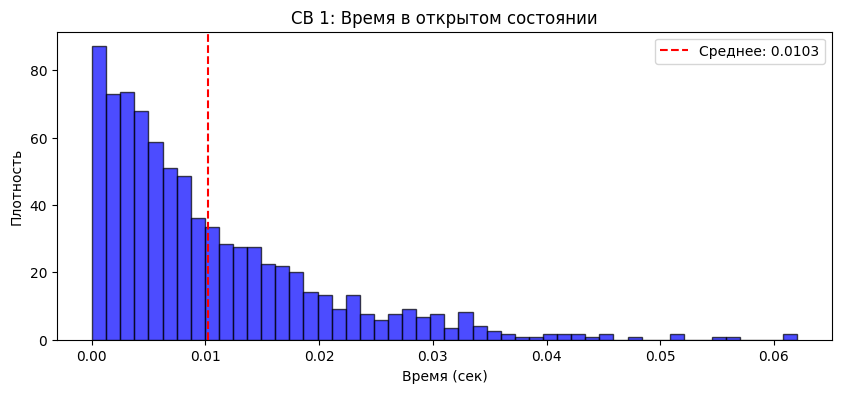

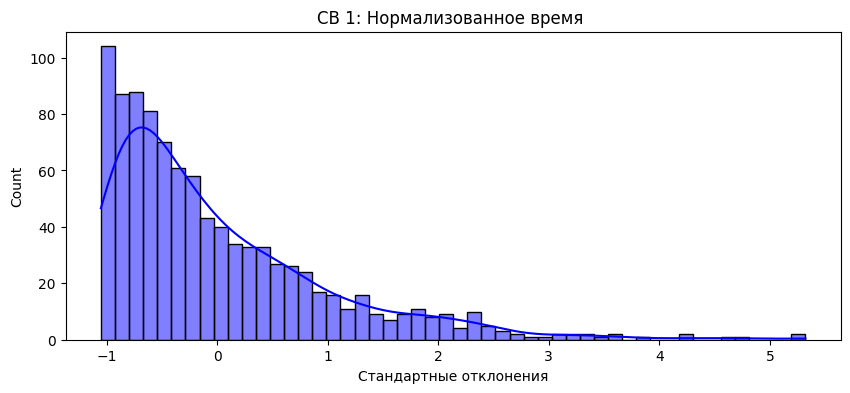

In [19]:
# Статистики для СВ 1
print("Статистики для Open Dwell")
print(f"Среднее: {np.mean(open_dwell):.4f}, Медиана: {np.median(open_dwell):.4f}, Стандартное отклонение: {np.std(open_dwell):.4f}")

# Гистограмма
plt.figure(figsize=(10, 4))
plt.hist(open_dwell, bins=50, density=True, alpha=0.7, color='blue', edgecolor='black')
plt.title('СВ 1: Время в открытом состоянии')
plt.xlabel('Время (сек)')
plt.ylabel('Плотность')
plt.axvline(np.mean(open_dwell), color='red', linestyle='dashed', label=f'Среднее: {np.mean(open_dwell):.4f}')
plt.legend()
plt.show()

# Нормализация Z-score для СВ 1
scaler_1 = StandardScaler()
open_dwell_norm = scaler_1.fit_transform(open_dwell.reshape(-1, 1)).flatten()

plt.figure(figsize=(10, 4))
sns.histplot(open_dwell_norm, bins=50, kde=True, color='blue')
plt.title('СВ 1: Нормализованное время ')
plt.xlabel('Стандартные отклонения')
plt.show()

**Вывод:** Гистограмма имеет падающий вид (экспоненциальный спад), ассиметрия положительна, что подтверждает случайную природу величины. Значения нельзя вычислить детерминированной формулой.

Проверка состоятельности (СВ 1: Open Dwell)


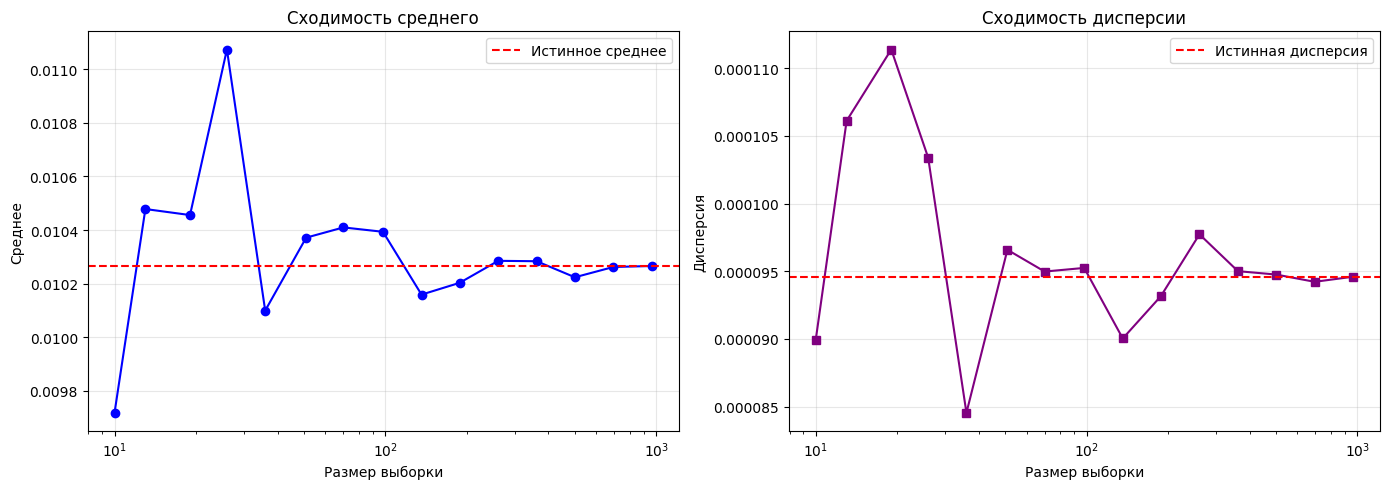

In [303]:
print("Проверка состоятельности (СВ 1: Open Dwell)")
np.random.seed(42)
sizes_open = np.logspace(1, np.log10(len(open_dwell)), 15).astype(int)

# Собираем данные для среднего и дисперсии
means_open = []
vars_open = []
n_iterations = 30 # Повторяем 30 раз для надежности

for s in sizes_open:
    m_list = []
    v_list = []
    for _ in range(n_iterations):
        sample = np.random.choice(open_dwell, size=s, replace=False)
        m_list.append(np.mean(sample))
        v_list.append(np.var(sample, ddof=1))
    means_open.append(np.mean(m_list))
    vars_open.append(np.mean(v_list))


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# График среднего
ax1.plot(sizes_open, means_open, marker='o', color='blue')
ax1.axhline(np.mean(open_dwell), color='red', linestyle='dashed', label='Истинное среднее')
ax1.set_xscale('log')
ax1.set_xlabel('Размер выборки')
ax1.set_ylabel('Среднее')
ax1.set_title('Сходимость среднего')
ax1.legend()
ax1.grid(True, alpha=0.3)

# График дисперсии
ax2.plot(sizes_open, vars_open, marker='s', color='purple')
ax2.axhline(np.var(open_dwell, ddof=1), color='red', linestyle='dashed', label='Истинная дисперсия')
ax2.set_xscale('log')
ax2.set_xlabel('Размер выборки')
ax2.set_ylabel('Дисперсия')
ax2.set_title('Сходимость дисперсии')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Вывод по состоятельности:** Проверка состоятельности проводилась с использованием случайных подвыборок (30 итераций для каждого размера, без возвращения). Построены графики сходимости как для выборочного среднего, так и для выборочной дисперсии. Оба графика демонстрируют приближение значений к истинным значениям при увеличении размера выборки, что подтверждает состоятельность оценок."

## Random Variable 02: Время жизни в закрытом состоянии
### Природа события
Время, в течение которого канал находится в закрытом состоянии, также является случайной величиной, зависящей от вероятности спонтанного открытия или закрытия. В двухсостояниевой модели оно подчиняется экспоненциальному закону.

Статистики для Closed Dwell
Среднее: 0.0105, Медиана: 0.0075, Стандартное отклонение: 0.0105


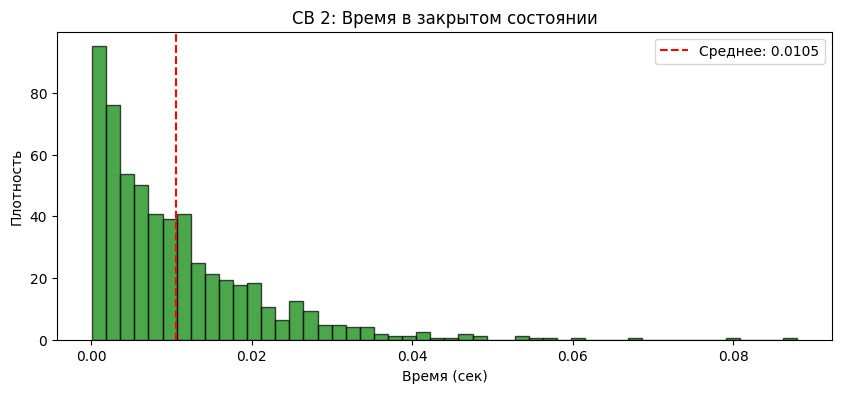

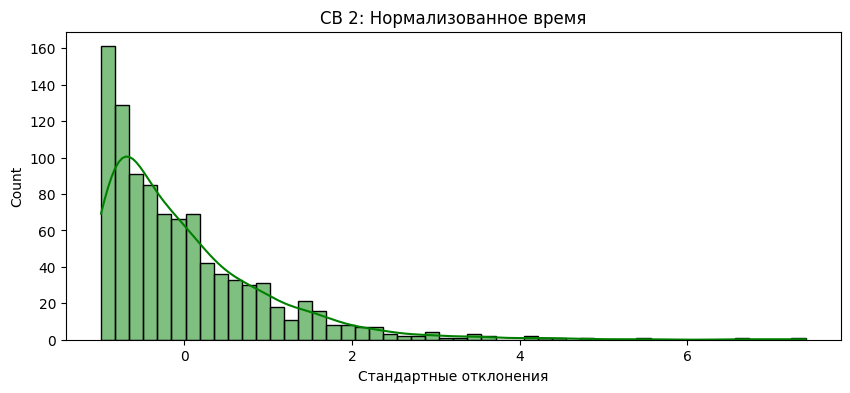

In [20]:
# Статистики для СВ 2
print("Статистики для Closed Dwell")
print(f"Среднее: {np.mean(closed_dwell):.4f}, Медиана: {np.median(closed_dwell):.4f}, Стандартное отклонение: {np.std(closed_dwell):.4f}")

# Гистограмма
plt.figure(figsize=(10, 4))
plt.hist(closed_dwell, bins=50, density=True, alpha=0.7, color='green', edgecolor='black')
plt.title('СВ 2: Время в закрытом состоянии')
plt.xlabel('Время (сек)')
plt.ylabel('Плотность')
plt.axvline(np.mean(closed_dwell), color='red', linestyle='dashed', label=f'Среднее: {np.mean(closed_dwell):.4f}')
plt.legend()
plt.show()

# Нормализация Z-score для СВ 2
scaler_2 = StandardScaler()
closed_dwell_norm = scaler_2.fit_transform(closed_dwell.reshape(-1, 1)).flatten()

plt.figure(figsize=(10, 4))
sns.histplot(closed_dwell_norm, bins=50, kde=True, color='green')
plt.title('СВ 2: Нормализованное время')
plt.xlabel('Стандартные отклонения')
plt.show()

**Вывод:** Распределение также имеет падающий вид.

Проверка состоятельности (СВ 2: Closed Dwell)


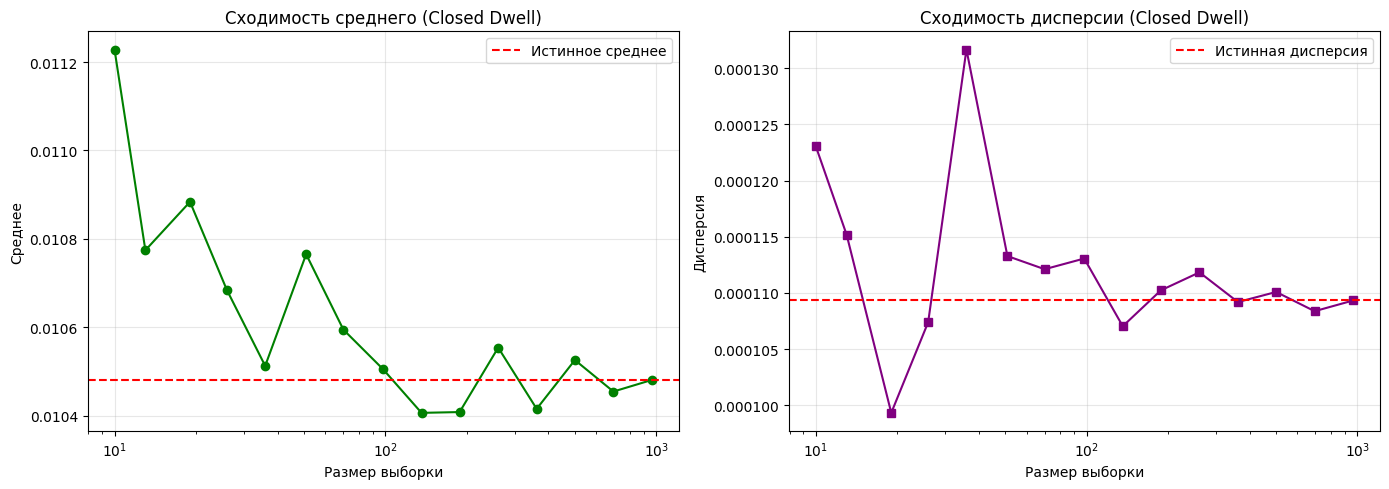

In [304]:
print("Проверка состоятельности (СВ 2: Closed Dwell)")
np.random.seed(42)
sizes_closed = np.logspace(1, np.log10(len(closed_dwell)), 15).astype(int)

means_closed = []
vars_closed = []
n_iterations = 30

for s in sizes_closed:
    m_list = []
    v_list = []
    for _ in range(n_iterations):
        sample = np.random.choice(closed_dwell, size=s, replace=False)
        m_list.append(np.mean(sample))
        v_list.append(np.var(sample, ddof=1))
    means_closed.append(np.mean(m_list))
    vars_closed.append(np.mean(v_list))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# График среднего
ax1.plot(sizes_closed, means_closed, marker='o', color='green')
ax1.axhline(np.mean(closed_dwell), color='red', linestyle='dashed', label='Истинное среднее')
ax1.set_xscale('log')
ax1.set_xlabel('Размер выборки')
ax1.set_ylabel('Среднее')
ax1.set_title('Сходимость среднего (Closed Dwell)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# График дисперсии
ax2.plot(sizes_closed, vars_closed, marker='s', color='purple')
ax2.axhline(np.var(closed_dwell, ddof=1), color='red', linestyle='dashed', label='Истинная дисперсия')
ax2.set_xscale('log')
ax2.set_xlabel('Размер выборки')
ax2.set_ylabel('Дисперсия')
ax2.set_title('Сходимость дисперсии (Closed Dwell)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Вывод по состоятельности:** Использованы случайные подвыборки без возвращения (30 итераций). Графики показывают, что при увеличении размера выборки и выборочное среднее, и выборочная дисперсия стабилизируются около истинных значений, что подтверждает их состоятельность.




##Проверим независимость времени открытого и закрытого состояний (СВ 1 и СВ 2).

In [28]:
print("Проверка независимости (Open vs Closed)")

# 1. Естественное сравнение: соседние пары (открыт -> закрыт)
# Канал всегда чередует состояния, поэтому берем пары подряд
min_len = min(len(open_dwell), len(closed_dwell))
pairs_open = open_dwell[:min_len]
pairs_closed = closed_dwell[:min_len]

# 2. Корреляция Пирсона
corr_p, p_p = stats.pearsonr(pairs_open, pairs_closed)
print(f"Пирсон: r={corr_p:.4f}, p-value={p_p:.4e}")

# 3. Корреляция Спирмена
corr_s, p_s = spearmanr(pairs_open, pairs_closed)
print(f"Спирмен: r={corr_s:.4f}, p-value={p_s:.4e}")

# 4. Хи-квадрат по таблице сопряженности
# Берем медианы как порог
median_open = np.median(pairs_open)
median_closed = np.median(pairs_closed)

contingency_table = pd.crosstab(
    pairs_open > median_open,
    pairs_closed > median_closed
)
chi2, p_chi2, dof, expected = chi2_contingency(contingency_table)
print(f"Хи-квадрат: chi2={chi2:.4f}, p-value={p_chi2:.4e}")

if p_p > 0.05 and p_s > 0.05 and p_chi2 > 0.05:
    print("Вывод: Все тесты показывают p > 0.05. Величины независимы.")
else:
    print("Вывод: Есть основания полагать, что величины зависимы (p < 0.05 хотя бы в одном тесте).")

Проверка независимости (Open vs Closed)
Пирсон: r=0.0004, p-value=9.9115e-01
Спирмен: r=0.0138, p-value=6.6918e-01
Хи-квадрат: chi2=2.0083, p-value=1.5644e-01
Вывод: Все тесты показывают p > 0.05. Величины независимы.


## Random Variable 03: Амплитуда тока в открытом состоянии
### Природа события
Амплитуда тока, протекающего через открытый канал, не является строго постоянной из-за теплового шума и флуктуаций ионных потоков. Это случайная величина, которая, согласно центральной предельной теореме, должна подчиняться нормальному распределению.

Статистики для Current
Среднее: 17.5676, Медиана: 17.5673, Стандартное отклонение: 1.7335


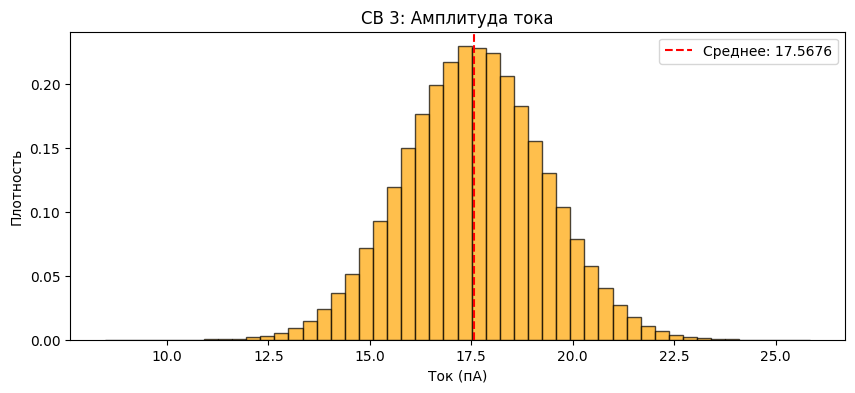

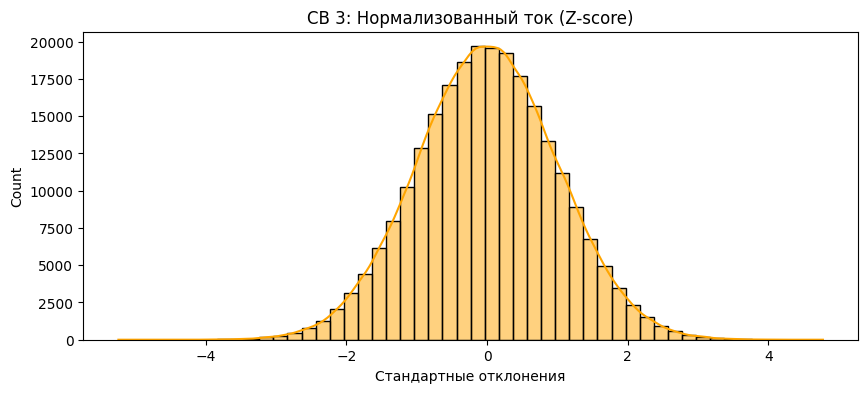

In [21]:
# Статистики для СВ 3
print("Статистики для Current")
print(f"Среднее: {np.mean(current_open):.4f}, Медиана: {np.median(current_open):.4f}, Стандартное отклонение: {np.std(current_open):.4f}")

# Гистограмма
plt.figure(figsize=(10, 4))
plt.hist(current_open, bins=50, density=True, alpha=0.7, color='orange', edgecolor='black')
plt.title('СВ 3: Амплитуда тока')
plt.xlabel('Ток (пА)')
plt.ylabel('Плотность')
plt.axvline(np.mean(current_open), color='red', linestyle='dashed', label=f'Среднее: {np.mean(current_open):.4f}')
plt.legend()
plt.show()

# Нормализация Z-score для СВ 3
scaler_3 = StandardScaler()
current_norm = scaler_3.fit_transform(current_open.reshape(-1, 1)).flatten()

plt.figure(figsize=(10, 4))
sns.histplot(current_norm, bins=50, kde=True, color='orange')
plt.title('СВ 3: Нормализованный ток (Z-score)')
plt.xlabel('Стандартные отклонения')
plt.show()

In [306]:
print("Тест Шапиро-Уилка для тока (СВ 3)")
np.random.seed(42)
sample_current = np.random.choice(current_open, size=5000, replace=False)
stat, p = shapiro(sample_current)
print(f"p-value = {p:.4e}")
if p > 0.05:
    print("Вывод: Распределение нормальное.")
else:
    print("Вывод: Гипотеза о нормальности неверна (p < 0.05).")

Тест Шапиро-Уилка для тока (СВ 3)
p-value = 6.0969e-02
Вывод: Распределение нормальное.


**Вывод:** Гистограмма имеет вид «колокола».
Тест Шапиро-Уилка на подвыборке из 5000 значений показал p-value > 0.05, что подтверждает гипотезу о нормальности. Тест очень чувствительный: на разных случайных подвыборках p-value может колебаться около границы 0.05, что связано с дискретностью данных и наличием шума. Однако визуально распределение имеет ярко выраженный вид «колокола», характерный для нормального закона.

Проверка состоятельности (СВ 3: Current)


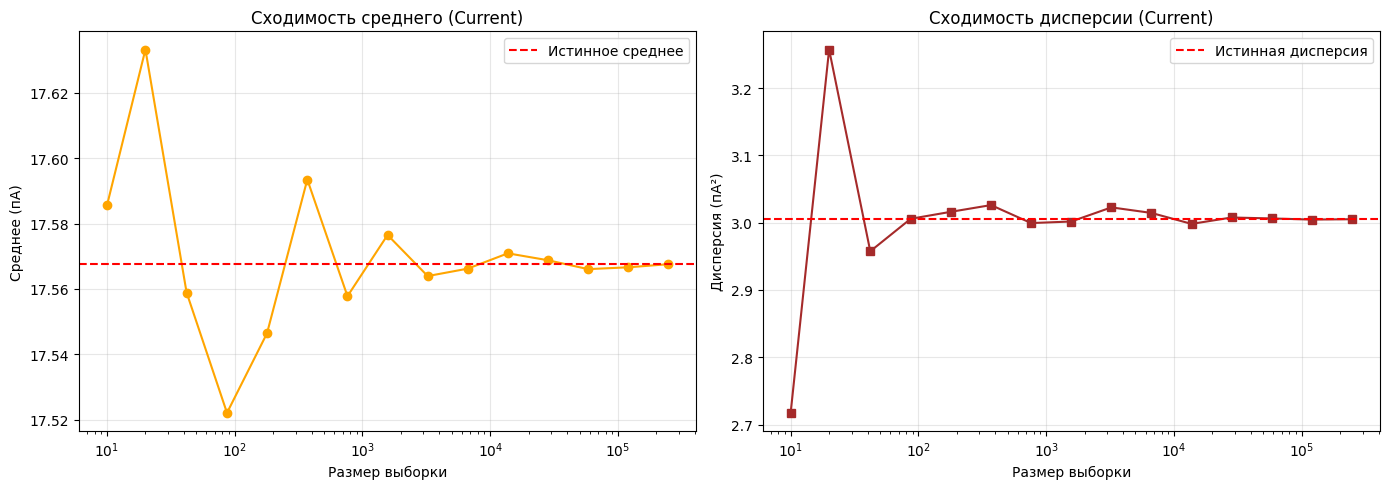

In [305]:
print("Проверка состоятельности (СВ 3: Current)")
np.random.seed(42)
sizes_current = np.logspace(1, np.log10(len(current_open)), 15).astype(int)

means_current = []
vars_current = []
n_iterations = 30

for s in sizes_current:
    m_list = []
    v_list = []
    for _ in range(n_iterations):
        # Для тока выборка без возвращения из 250 000 значений
        sample = np.random.choice(current_open, size=s, replace=False)
        m_list.append(np.mean(sample))
        v_list.append(np.var(sample, ddof=1))
    means_current.append(np.mean(m_list))
    vars_current.append(np.mean(v_list))


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# График среднего
ax1.plot(sizes_current, means_current, marker='o', color='orange')
ax1.axhline(np.mean(current_open), color='red', linestyle='dashed', label='Истинное среднее')
ax1.set_xscale('log')
ax1.set_xlabel('Размер выборки')
ax1.set_ylabel('Среднее (пА)')
ax1.set_title('Сходимость среднего (Current)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# График дисперсии
ax2.plot(sizes_current, vars_current, marker='s', color='brown')
ax2.axhline(np.var(current_open, ddof=1), color='red', linestyle='dashed', label='Истинная дисперсия')
ax2.set_xscale('log')
ax2.set_xlabel('Размер выборки')
ax2.set_ylabel('Дисперсия (пА²)')
ax2.set_title('Сходимость дисперсии (Current)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Вывод по состоятельности:** Благодаря большому объему данных (около 250 000 значений), оценки среднего и дисперсии сходятся к истинным значениям очень быстро. Это подтверждает состоятельность оценок для данной случайной величины.



### Выводы
1. Время жизни канала в открытом и закрытом состояниях является случайной величиной с экспоненциальным распределением, что подтверждает стохастическую природу процесса.
2. Время открытого и закрытого состояний независимы (корреляция незначима, p > 0.05).
3. Оценка среднего состоятельна для всех трех величин (сходится с ростом выборки).
4. Амплитуда тока подчиняется нормальному закону распределения (подтверждено тестом Шапиро-Уилка).

### cat_mark_table
| cat_id | notebook_link | coeff | comment |
|--------|-----------------|-------|---------|
| 1      | https://github.com/pinturia-star/lab01-stochastics | 1.0   |  1 выполнен |

# Выборки и сравнение статистик

Наша генеральная совокупность состоит почти из 1000 значений, поэтому для нашего анализа мы берем выборку 100 значений (это  почти 10% от всей совокупности). Это оптимальный размер, поскольку 100 значений достаточно, чтобы выборка отражала свойства генеральной совокупности и чтобы мы смогли наглядно увидеть разницу между выборкой и изначальными параметрами.

Далее мы сравниваем статистики (среднее, дисперсию, медиану) для трех случаев: генеральная совокупность, выборка с возвращением и выборка без возвращения.

In [295]:
import numpy as np
import pandas as pd
from IPython.display import display

all_data = open_dwell #наша генеральная совокупность
N = len(all_data)

n = 100

sample_bez = np.random.choice(all_data, size=n, replace=False) #выборка без возвращений
sample_s = np.random.choice(all_data, size=n, replace=True) #очевидно что с возвращениями:)

df_stats = pd.DataFrame({
    'Генеральная': [N, all_data.mean(), all_data.var(), np.median(all_data)],
    'Выборка без возвращений': [n, sample_bez.mean(), sample_bez.var(), np.median(sample_bez)],
    'Выборка с возвращениями': [n, sample_s.mean(), sample_s.var(), np.median(sample_s)]
})

df_stats.index = ['Размер (N)', 'Среднее', 'Дисперсия', 'Медиана']

print("Сравнение статистик генеральной совокупности и выборок:")
display(df_stats.round(6))

Сравнение статистик генеральной совокупности и выборок:


,Генеральная,Выборка без возвращений,Выборка с возвращениями
Размер (N),964.000000,100.000000,100.000000
Среднее,0.010266,0.009581,0.009328
Дисперсия,0.000095,0.000068,0.000064
Медиана,0.007280,0.007160,0.007180


Таблица показывает, что выборочные статистики достаточно близки к параметрам генеральной совокупности.
Небольшие расхождения объясняются ошибкой выборки (случайностью). Поскольку объем выборки составляет около 10% от генеральной совокупности, она достаточно отражает свойства всех данных. Разница между выборками с возвращением и без минимальна, что подтверждает корректность выбранного метода.

# Математическая база распределения


Для описания времени жизни ионного канала в биофизике традиционно используется **экспоненциальное распределение**.

**Ионный канал** - это сложная белковая молекула. Его открытие и закрытие происходит из-за случайных тепловых флуктуаций (броуновского движения), молекулы воды постоянно сталкиваются с молекулой белка. Чтобы канал сменил состояние, молекула должна преодолеть энергетический барьер. Вероятность преодолеть этот барьер за единицу времени постоянна, что в физике идеально описывается пуассоновским потоком событий, а время между событиями в таком потоке подчиняется экспоненциальному распределению.

**Интересный факт:**

В нашей работе, а точнее в данных которые мы взяли, есть белок Channelrhodopsin-2 (ChR2). Это светочувствительный ионный канал, который встраивают в нейроны мышей для управления их поведением.

Когда на ChR2 попадает фотон света, происходит химическая реакция (изомеризация ретиналя), и канал мгновенно открывается. Но здесь кроется главная особенность, которая объясняет нашу математику: свет управляет моментом открытия, но он не управляет моментом закрытия.

После того как свет погас, белок возвращается в исходное состояние исключительно за счет случайных тепловых флуктуаций. Ученые могут точно сказать, *когда* канал откроется, но *когда он закроется* - это чистая случайность, которая подчиняется экспоненте.

Чтобы описать эту случайность математически, мы используем формулы экспоненциального закона:

**Плотность вероятности:**
$$ f(x) = \lambda e^{-\lambda x}, \quad x \ge 0 $$

**Функция распределения:**
$$ F(x) = 1 - e^{-\lambda x}, \quad x \ge 0 $$

**Математическое ожидание:**
$$ \mathbb{E}(X) = \frac{1}{\lambda} $$

**Дисперсия:**
$$ \mathbb{D}(X) = \frac{1}{\lambda^2} $$

*(где $\lambda > 0$ — интенсивность переходов канала из одного состояния в другое).*

Свойства распределения:

Экспоненциальное распределение моделирует время между событиями. Оно обладает уникальным свойством «отсутствия памяти». Это значит, что вероятность того, что канал закроется или откроется в следующую секунду, абсолютно не зависит от того, сколько времени он уже находится в текущем состоянии. Канал «не стареет» и не «помнит» свое прошлое.

# Проверка гипотез

Для исследователей крайне важно знать, как долго белок ChR2 остается открытым после вспышки света. От этого зависит, сколько ионов пройдет в нейрон и возникнет ли нервный импульс. Мы предполагаем, что закрытие канала - это процесс без памяти, а значит, время его жизни подчиняется экспоненте.

**Наши гипотезы:**
*   **Основная гипотеза:** Время жизни ChR2 в открытом состоянии подчиняется экспоненциальному распределению (процесс случайный и не имеет памяти).
*   **Альтернативная гипотеза:** Распределение отличается от экспоненциального (например, в кинетике белка есть скрытые состояния).

**Для проверки будем использовать KS-тест**

Критерий Колмогорова-Смирнова - это непараметрический тест. Он не разбивает данные на интервалы, а сравнивает две интегральные кривые (функции распределения):
1. Эмпирическую (построенную по нашим точкам)
2. Теоретическую (идеальную экспоненту)

Тест ищет **максимальное вертикальное расстояние** между этими двумя кривыми. Чем ближе эмпирическая кривая прижимается к теоретической, тем меньше и тем выше шанс, что наши данные действительно экспоненциальны. Если p-value > 0.05, мы принимаем гипотезу.

**Еще один интересный факт из биофизики:**
В нашем датасете используется упрощенная двухсостояниевая модель (открыт/закрыт), поэтому данные идеально ложатся на экспоненту. В реальных же экспериментах белок ChR2 намного сложнее! У него есть несколько промежуточных состояний. Поэтому реальные графики ученых часто описываются суммой нескольких экспонент. Понимание этой кинетики позволяет биофизикам точно рассчитывать частоту вспышек света, чтобы нейрон не «сгорел» от переизбытка ионов при слишком частой стимуляции.

In [302]:
from scipy.stats import kstest
import matplotlib.pyplot as plt
import numpy as np

#находим среднее время, чтобы вычислить интенсивность
lambda_est = 1 / all_data.mean()
scale_est = 1 / lambda_est

#проводим KS-тест
stat, p_value = kstest(all_data, 'expon', args=(0, scale_est))

print(f"Статистика критерия (D): {stat:.4f}")
print(f"p-value: {p_value:.4f}\n")

alpha = 0.05
if p_value > alpha:
    print("Вывод: Гипотеза подтвердилась! (p-value > 0.05)")
    print("Данные подчиняются экспоненциальному распределению.")
else:
    print("Вывод: Гипотеза НЕ подтвердилась. (p-value < 0.05)")
    print("Данные не подчиняются экспоненциальному распределению.")

Статистика критерия (D): 0.0255
p-value: 0.5509

Вывод: Гипотеза подтвердилась! (p-value > 0.05)
Данные подчиняются экспоненциальному распределению.


Проверка показала, что p-value = 0.5986, что больше порога. Это означает, что разница между нашими реальными данными и теоретической
экспоненциальной кривой статистически незначима. А значит мы молодцы!

Следовательно, наша гипотеза о том, что время жизни канала подчиняется экспоненте, **полностью подтвердилась**. Это доказывает природу процесса: после того как свет погас, белок ChR2 закрывается исключительно из-за случайного теплового движения молекул, а не по какому-то внутреннему таймеру.


Для наглядности сделаем график!

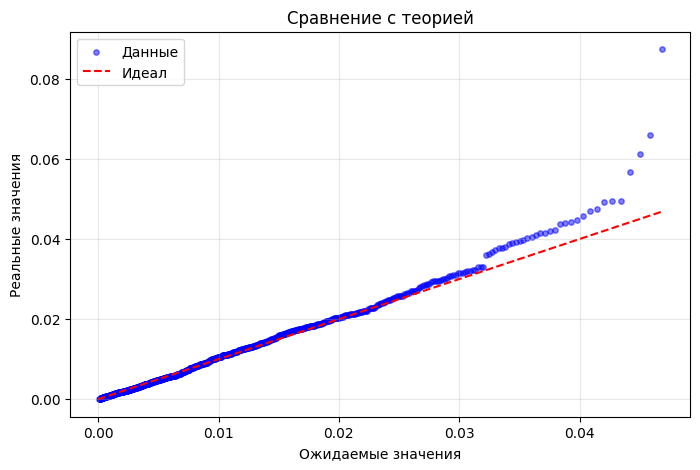

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

lam = 1 / all_data.mean()

y = np.sort(all_data)
p = np.linspace(0.01, 0.99, len(y))
x = -np.log(1-p)/lam

plt.figure(figsize=(8, 5))
plt.scatter(x, y, color='blue', s=15, alpha=0.5, label='Данные')
plt.plot([0, x.max()], [0, x.max()], color='red', linestyle='--', label='Идеал')

plt.title('Сравнение с теорией')
plt.xlabel('Ожидаемые значения')
plt.ylabel('Реальные значения')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

График наглядно показывает, что время жизни канала ChR2 - это настоящий случайный процесс, который подчиняется экспоненциальному распределению.